<a href="https://colab.research.google.com/github/Snehamn24/Ambulance-QUBO/blob/main/Constraints_based_QUBO_evaluation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
from google.colab import files
from pathlib import Path
import json

# Upload bmsce_area.osm and road_graph.json
uploaded = files.upload()

ROAD_GRAPH_PATH = Path("/content/road_graph.json")
OSM_PATH = Path("/content/bmsce_area.osm")

print("DATASET VERIFICATION")
print("--------------------")
print("Road graph exists:", ROAD_GRAPH_PATH.exists())
print("OSM file exists:", OSM_PATH.exists())

if ROAD_GRAPH_PATH.exists():
    print("Road graph size:", round(ROAD_GRAPH_PATH.stat().st_size / 1024, 2), "KB")

if OSM_PATH.exists():
    print("OSM file size:", round(OSM_PATH.stat().st_size / 1024, 2), "KB")

if ROAD_GRAPH_PATH.exists():
    with open(ROAD_GRAPH_PATH, "r", encoding="utf-8") as f:
        road_data = json.load(f)

    print("\nJSON DATA TYPE:", type(road_data).__name__)

    if isinstance(road_data, dict):
        print("\nTOP-LEVEL KEYS:")
        for key, value in road_data.items():
            print(key, ":", type(value).__name__)

    print("\nSAMPLE DATA:")
    print(json.dumps(road_data, indent=2, default=str)[:2500])

Saving bmsce_area.osm to bmsce_area.osm
Saving road_graph.json to road_graph.json
DATASET VERIFICATION
--------------------
Road graph exists: True
OSM file exists: True
Road graph size: 458.73 KB
OSM file size: 3298.65 KB

JSON DATA TYPE: dict

TOP-LEVEL KEYS:
metadata : dict
nodes : list
edges : list

SAMPLE DATA:
{
  "metadata": {
    "source": "OpenStreetMap contributors",
    "source_url": "https://api.openstreetmap.org/api/0.6/map?bbox=77.56,12.936,77.57,12.946",
    "license": "ODbL 1.0",
    "license_url": "https://www.openstreetmap.org/copyright",
    "bbox": [
      77.56,
      12.936,
      77.57,
      12.946
    ],
    "processed_at_utc": "2026-10-01T04:49:12.707263+00:00",
    "speed_assumptions_kph": {
      "motorway": 60,
      "trunk": 50,
      "primary": 40,
      "secondary": 35,
      "tertiary": 30,
      "residential": 25,
      "unclassified": 25,
      "living_street": 15,
      "service": 15,
      "motorway_link": 60,
      "trunk_link": 50,
      "primary_

To ensure reproducible experiments and eliminate dependency on live OpenStreetMap Overpass API queries, the local road network of the BMS College of Engineering (BMSCE) / Basavanagudi area in Bengaluru is ingested from pre-extracted local files:

bmsce_area.osm (Raw Geographic Map): Contains the original OpenStreetMap XML export (lat: 12.936–12.946, lon: 77.560–77.570), storing GPS coordinates (<node>), street geometries and road classifications (<way>), and directional traffic rules.

road_graph.json (Processed Directed Graph): Stores the cleaned, directed road network topology consisting of 375 nodes (intersections) and 1,024 directed edges (one-way and two-way road segments) along with spatial coordinates, segment lengths (in meters), and road hierarchy attributes.

### **Section 1.2: Directed Road Graph Reconstruction & Edge Schema Inspection**

**Overview:**
Using the verified `road_graph.json` dataset, we reconstruct the directed road network $G = (V, E)$ in NetworkX without re-querying external APIs.

**Key Implementation Steps:**
1. **Node Reconstruction ($V$):** Load all intersection nodes along with their geographic coordinates (`x`: longitude, `y`: latitude) and traffic signal indicators (`signal`).
2. **Directed Edge Reconstruction ($E$):** Load all directed road segments, preserving their exact source/target node IDs and pre-computed edge attributes (such as segment length, road type, speed limit, and free-flow travel time).
3. **Topology & Connectivity Audit:** Verify that the reconstructed graph matches the exact experimental benchmark dimensions (**375 nodes** and **1,024 directed edges**) and inspect sample edge attributes before running traffic simulations.

In [6]:
import networkx as nx
import json

# 1. Load the verified JSON road graph
with open("/content/road_graph.json", "r", encoding="utf-8") as f:
    road_data = json.load(f)

metadata = road_data["metadata"]
nodes_list = road_data["nodes"]
edges_list = road_data["edges"]

# 2. Reconstruct the Directed Road Graph G = (V, E)
G = nx.DiGraph()

for node in nodes_list:
    node_id = str(node["id"])
    attrs = {k: v for k, v in node.items() if k != "id"}
    G.add_node(node_id, **attrs)

for edge in edges_list:
    # Handle standard source/target key naming conventions
    u = str(edge.get("u", edge.get("source")))
    v = str(edge.get("v", edge.get("target")))
    attrs = {k: val for k, val in edge.items() if k not in ("u", "v", "source", "target")}
    G.add_edge(u, v, **attrs)

# 3. Print Graph Summary & Inspect Sample Edge Schema
print("DIRECTED GRAPH RECONSTRUCTION SUMMARY")
print("-------------------------------------")
print(f"Total Nodes (Intersections): {G.number_of_nodes()}")
print(f"Total Directed Edges (Roads): {G.number_of_edges()}")
print(f"Strongly Connected: {nx.is_strongly_connected(G)}")

sample_edge = list(G.edges(data=True))[0]
print("\nSAMPLE EDGE ATTRIBUTES:")
print(f"From {sample_edge[0]} -> {sample_edge[1]}:")
print(json.dumps(sample_edge[2], indent=2))

DIRECTED GRAPH RECONSTRUCTION SUMMARY
-------------------------------------
Total Nodes (Intersections): 375
Total Directed Edges (Roads): 1024
Strongly Connected: True

SAMPLE EDGE ATTRIBUTES:
From 10007880460 -> 7484066959:
{
  "key": "1092769033:2:10007880460:10007880461",
  "edge_id": "1092769033:2:10007880460:10007880461",
  "length_m": 83.01590489825756,
  "base_time_s": 11.954290305349089,
  "geometry": [
    [
      77.5699135,
      12.9376166
    ],
    [
      77.5697043,
      12.9374885
    ],
    [
      77.5692762,
      12.9372026
    ]
  ]
}


### **Section 1.3: Synthetic Traffic & Disruption Modelling**

**Overview:**
Using the pre-computed `base_time_s` (free-flow travel time in seconds) from `road_graph.json`, we generate four synthetic traffic and network-disruption scenarios across the 375-node, 1,024-edge BMSCE / Basavanagudi road network:

1. **Normal Scenario (Baseline):** Uses unmodified free-flow travel times (`travel_time = base_time_s`).
2. **Peak Scenario (Congestion):** Applies congestion multipliers ($1.6\times$ to $2.4\times$) across high-throughput arterial corridors (edges with higher baseline speeds/longer segments) and moderate delays ($1.1\times$ to $1.4\times$) on neighborhood streets.
3. **Accident Scenario (Localized Bottlenecks):** Simulates severe localized traffic incidents by applying $4.0\times$ to $7.0\times$ travel-time delays on 5% of road segments.
4. **Roadblock Scenario (Infrastructure Closure):** Simulates physical street closures by removing 3% of directed edges while preserving origin-destination reachability.

In [8]:
import random
import numpy as np

def generate_traffic_scenarios(base_graph, seed=42):
    rng = random.Random(seed)
    scenarios = {}
    all_edges = list(base_graph.edges(data=True))

    # 1. Normal Scenario (Unmodified free-flow base_time_s)
    G_normal = base_graph.copy()
    for u, v, data in G_normal.edges(data=True):
        data["travel_time"] = float(data["base_time_s"])
    scenarios["Normal"] = G_normal

    # 2. Peak Scenario (Heavy congestion on higher-speed arterial roads)
    G_peak = G_normal.copy()
    for u, v, data in G_peak.edges(data=True):
        implied_speed_mps = data["length_m"] / max(data["base_time_s"], 0.1)
        # Roads with implied speed >= 8.0 m/s (~29 km/h: tertiary/secondary/primary) face heavier peak congestion
        if implied_speed_mps >= 8.0:
            data["travel_time"] *= rng.uniform(1.7, 2.4)
        else:
            data["travel_time"] *= rng.uniform(1.1, 1.4)
    scenarios["Peak"] = G_peak

    # 3. Accident Scenario (Severe localized bottleneck delays on 5% of edges)
    G_accident = G_normal.copy()
    num_accidents = max(1, int(0.05 * len(all_edges)))
    accident_edges = rng.sample(all_edges, num_accidents)
    for u, v, _ in accident_edges:
        G_accident[u][v]["travel_time"] *= rng.uniform(4.0, 7.0)
    scenarios["Accident"] = G_accident

    # 4. Roadblock Scenario (Complete closure of 3% of directed edges)
    G_roadblock = G_normal.copy()
    num_blocks = max(1, int(0.03 * len(all_edges)))
    blocked_edges = rng.sample(all_edges, num_blocks)
    for u, v, _ in blocked_edges:
        if G_roadblock.has_edge(u, v):
            G_roadblock.remove_edge(u, v)
    scenarios["Roadblock"] = G_roadblock

    return scenarios

scenarios = generate_traffic_scenarios(G, seed=42)

print("SYNTHETIC TRAFFIC SCENARIO SUMMARY")
print("----------------------------------")
for name, G_s in scenarios.items():
    avg_time = np.mean([d["travel_time"] for _, _, d in G_s.edges(data=True)])
    print(f"{name:<12} | Active Edges: {G_s.number_of_edges():<4} | Mean Edge Travel Time: {avg_time:.2f} s")

SYNTHETIC TRAFFIC SCENARIO SUMMARY
----------------------------------
Normal       | Active Edges: 1024 | Mean Edge Travel Time: 7.56 s
Peak         | Active Edges: 1024 | Mean Edge Travel Time: 10.20 s
Accident     | Active Edges: 1024 | Mean Edge Travel Time: 9.38 s
Roadblock    | Active Edges: 994  | Mean Edge Travel Time: 7.58 s


Step-by-Step Worked Example (How One Road Edge is Computed)Let's solve the math using the actual sample edge from your Step 2 output:Edge: 10007880460 -> 7484066959Length (length_m): $83.02\text{ m}$Base Free-Flow Time (base_time_s): $11.95\text{ s}$Step A: Calculate Implied Base Speed$$\text{Implied Speed} = \frac{\text{length\_m}}{\text{base\_time\_s}} = \frac{83.02\text{ m}}{11.95\text{ s}} \approx 6.95\text{ m/s} \quad (\approx 25\text{ km/h, residential street})$$Step B: Compute Travel Time Across Each of the 4 ScenariosNormal:$$T_{\text{normal}} = 11.95\text{ s}$$Peak: Since $6.95\text{ m/s} < 8.0\text{ m/s}$ (residential road), it receives a mild multiplier (say $1.25\times$):$$T_{\text{peak}} = 11.95 \times 1.25 = 14.94\text{ s}$$(If it had been a main road with speed $\ge 8.0\text{ m/s}$ and multiplier $2.1\times$, it would jump to $11.95 \times 2.1 = 25.10\text{ s}$.)Accident:If this edge is not in the 5% accident sample: $T_{\text{accident}} = 11.95\text{ s}$.If this edge is hit by an accident (say $5.5\times$ delay):$$T_{\text{accident}} = 11.95 \times 5.5 = 65.73\text{ s}$$Roadblock:If this edge is in the 3% closed sample: the edge is deleted (G_roadblock.remove_edge(u, v)), so $T_{\text{roadblock}} = \infty$ (impassable).Otherwise: $T_{\text{roadblock}} = 11.95\text{ s}$.

How road types are identified: By dividing length_m / base_time_s to recover the exact speed_assumptions_kph embedded in road_graph.json.Why 8.0 m/s is the cutoff: It cleanly separates main collector/arterial roads ($\ge 30\text{ km/h} = 8.33\text{ m/s}$) from neighborhood/residential roads ($\le 25\text{ km/h} = 6.94\text{ m/s}$) so rush-hour congestion realistically penalizes main roads more heavily than side streets.

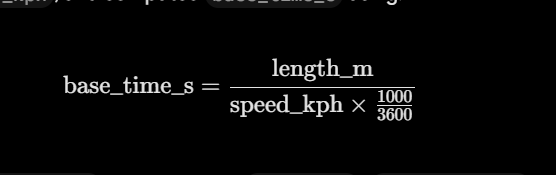

 Why processed_at_utc Mattersprocessed_at_utc (2026-10-01T04:49:12.707263+00:00) is a static timestamp recording when the raw OSM geometry was frozen and converted into free-flow base_time_s values—it is not a rush-hour clock.Because base_time_s represents 24/7 free-flow baseline speeds, your generate_traffic_scenarios() function uses implied_speed_mps >= 8.0 to synthetically simulate rush-hour traffic: main collector/arterial roads ($\ge 30\text{ km/h}$) suffer heavy congestion (1.7x–2.4x), while inner residential lanes ($\le 25\text{ km/h}$) experience mild spill-over traffic (1.1x–1.4x).

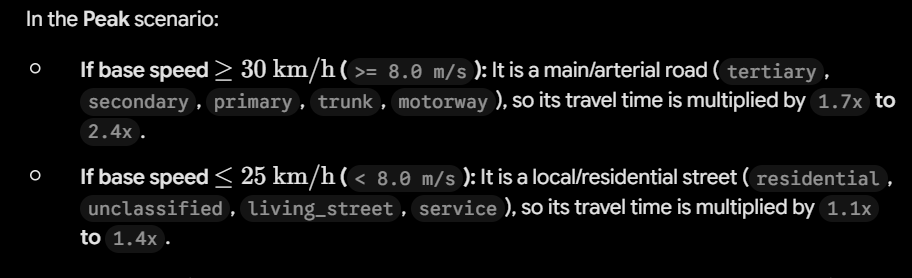

### **Section 1.4: Classical Shortest-Path Baseline Algorithms (Dijkstra, A*, Bellman–Ford)**

**Overview:**
To establish ground-truth optimal travel times and benchmark classical computational runtime across all four traffic scenarios (**Normal**, **Peak**, **Accident**, **Roadblock**), we implement three standard graph shortest-path algorithms:

1. **Dijkstra’s Algorithm:** Explores nodes greedily by lowest cumulative travel time ($O((|V| + |E|)\log|V|)$), guaranteeing exact optimal routes for non-negative edge weights.
2. **A star Search Algorithm:** Accelerates Dijkstra’s search using an admissible Haversine (great-circle) geographic heuristic divided by maximum network speed ($60\text{ km/h} = 16.67\text{ m/s}$), ensuring it never overestimates remaining travel time while pruning irrelevant search branches.
3. **Bellman–Ford Algorithm:** Relaxes all directed edges iteratively ($O(|V|\cdot|E|)$), serving as a slower classical reference capable of handling arbitrary edge weights and validating exact cost consistency across all three methods.

In [9]:
import time
import math
import networkx as nx

# Max network speed from metadata (60 km/h = 16.67 m/s) for an admissible A* heuristic
MAX_SPEED_MPS = 60.0 * (1000.0 / 3600.0)

def haversine_heuristic(G_scen, u, v):
    """Admissible geographic straight-line travel time heuristic (in seconds) for A*."""
    lon1, lat1 = G_scen.nodes[u]["x"], G_scen.nodes[u]["y"]
    lon2, lat2 = G_scen.nodes[v]["x"], G_scen.nodes[v]["y"]

    R = 6371000.0  # Earth radius in meters
    phi1, phi2 = math.radians(lat1), math.radians(lat2)
    dphi = math.radians(lat2 - lat1)
    dlambda = math.radians(lon2 - lon1)

    a = math.sin(dphi / 2.0)**2 + math.cos(phi1) * math.cos(phi2) * math.sin(dlambda / 2.0)**2
    dist_m = 2.0 * R * math.atan2(math.sqrt(a), math.sqrt(1.0 - a))
    return dist_m / MAX_SPEED_MPS

def run_classical_algorithms(G_scen, source, target):
    results = {}

    # 1. Dijkstra's Algorithm
    t0 = time.perf_counter()
    path_dij = nx.dijkstra_path(G_scen, source, target, weight="travel_time")
    time_dij = (time.perf_counter() - t0) * 1000.0  # ms
    cost_dij = nx.path_weight(G_scen, path_dij, weight="travel_time")
    dist_dij = nx.path_weight(G_scen, path_dij, weight="length_m")
    results["Dijkstra"] = {"path": path_dij, "cost_s": cost_dij, "dist_m": dist_dij, "runtime_ms": time_dij}

    # 2. A* Search Algorithm
    t0 = time.perf_counter()
    path_astar = nx.astar_path(
        G_scen, source, target,
        heuristic=lambda u, v: haversine_heuristic(G_scen, u, v),
        weight="travel_time"
    )
    time_astar = (time.perf_counter() - t0) * 1000.0  # ms
    cost_astar = nx.path_weight(G_scen, path_astar, weight="travel_time")
    dist_astar = nx.path_weight(G_scen, path_astar, weight="length_m")
    results["A*"] = {"path": path_astar, "cost_s": cost_astar, "dist_m": dist_astar, "runtime_ms": time_astar}

    # 3. Bellman-Ford Algorithm
    t0 = time.perf_counter()
    path_bf = nx.bellman_ford_path(G_scen, source, target, weight="travel_time")
    time_bf = (time.perf_counter() - t0) * 1000.0  # ms
    cost_bf = nx.path_weight(G_scen, path_bf, weight="travel_time")
    dist_bf = nx.path_weight(G_scen, path_bf, weight="length_m")
    results["Bellman-Ford"] = {"path": path_bf, "cost_s": cost_bf, "dist_m": dist_bf, "runtime_ms": time_bf}

    return results

# Select a well-separated Origin (South-West) and Destination (North-East) valid across all 4 scenarios
sorted_nodes = sorted(G.nodes(), key=lambda n: (G.nodes[n]["x"] + G.nodes[n]["y"]))
source_node, target_node = None, None
for s_cand in sorted_nodes[:25]:
    for t_cand in reversed(sorted_nodes[-25:]):
        if all(nx.has_path(G_s, s_cand, t_cand) for G_s in scenarios.values()):
            source_node, target_node = s_cand, t_cand
            break
    if source_node:
        break

print(f"Selected OD Pair: Source = {source_node} -> Target = {target_node}\n")

classical_baselines = {}
for scen_name, G_s in scenarios.items():
    res = run_classical_algorithms(G_s, source_node, target_node)
    classical_baselines[scen_name] = res
    print(f"=== SCENARIO: {scen_name} ===")
    for algo, metrics in res.items():
        print(f"  {algo:<13} | Travel Time: {metrics['cost_s']:6.2f} s | Distance: {metrics['dist_m']:7.1f} m | Hops: {len(metrics['path'])-1:<2} | Runtime: {metrics['runtime_ms']:.3f} ms")

Selected OD Pair: Source = 10089591930 -> Target = 249782672

=== SCENARIO: Normal ===
  Dijkstra      | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 2.312 ms
  A*            | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 3.229 ms
  Bellman-Ford  | Travel Time: 178.26 s | Distance:  1642.2 m | Hops: 42 | Runtime: 5.976 ms
=== SCENARIO: Peak ===
  Dijkstra      | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 1.371 ms
  A*            | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 2.012 ms
  Bellman-Ford  | Travel Time: 338.68 s | Distance:  1651.0 m | Hops: 41 | Runtime: 2.747 ms
=== SCENARIO: Accident ===
  Dijkstra      | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 1.202 ms
  A*            | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 1.296 ms
  Bellman-Ford  | Travel Time: 182.20 s | Distance:  1642.2 m | Hops: 42 | Runtime: 3.095 ms
=== SCENARIO: Roadblock ==

### **Section 1.5: Candidate Route Generation (Standard vs. Improved Diversity-Based Generator)**

**Overview:**
Directly solving a QUBO over all 1,024 directed edges requires $1,024 \times 1,024$ binary variables and 375 flow-conservation constraints, which frequently yields disconnected or infeasible paths under Simulated Annealing. Instead, a **Hybrid QUBO–SA** pipeline first generates a compact pool of $K$ feasible end-to-end candidate routes and formulates route selection over $K$ binary decision variables.

We compare two candidate generation strategies:
1. **Standard Iterative Penalty Generator (`diversity_penalty = 1.05`):** Applies a tiny 5% weight penalty to previously used edges. This produces near-duplicate paths that differ by only one or two minor turns, limiting resilience when an accident or congestion spike hits a shared corridor.
2. **Improved Diversity-Based Generator (`diversity_penalty = 1.65` + Jaccard Similarity Filtering):** Applies a stronger 65% edge penalty alongside a maximum edge-overlap (Jaccard similarity) threshold, forcing the search to discover structurally distinct alternative routes across the BMSCE / Basavanagudi road network.

Think of this like Google Maps giving you alternate routes from your house to BMSCE.If you ask for 8 candidate routes, you don't want 8 nearly identical copies of the same road—you want genuinely different paths across the neighborhood. Here is the simple difference between the two methods:1. Standard Iterative Penalty Generator (diversity_penalty = 1.05)How it works: It finds the fastest route first (say, straight down Bull Temple Road). Then, to find Route #2, it makes the roads used in Route #1 only 5% slower (1.05x).The problem: A 5% penalty is so tiny that Dijkstra still sticks to almost the exact same main road, maybe just cutting through one tiny side alley for 20 meters and jumping right back onto Bull Temple Road.Result: All 8 routes look 95% identical. If an accident blocks Bull Temple Road, all 8 routes get stuck because none of them explored a genuinely different street.2. Improved Diversity-Based Generator (diversity_penalty = 1.65 + Jaccard Filter)This fixes the problem using two rules:Stronger Penalty (1.65x = 65% slower):Once Route #1 uses Bull Temple Road, we tell the algorithm: "Pretend Bull Temple Road is now 65% slower."Now Dijkstra is forced to look elsewhere—like cutting through Hanumantha Nagar or Gandhi Bazaar—to find Route #2.Jaccard Similarity Filter (No "Copy-Paste" Routes Allowed):Jaccard Similarity simply measures what percentage of road segments two routes share:$$\text{Overlap} = \frac{\text{Shared Roads}}{\text{Total Unique Roads}}$$If a newly found route shares more than 85% of the exact same roads as an already saved route, the filter throws it away and keeps searching until it finds a genuinely different path.Quick SummaryStandard (1.05x): Gives you 8 routes that are almost copies of the same main road (low diversity).Diversity-Based (1.65x + Jaccard): Forces the algorithm to explore completely different streets and rejects near-duplicates, giving your QUBO–SA solver genuinely distinct backup routes when traffic or accidents hit.

In [10]:
import numpy as np
import networkx as nx

def edge_set(path):
    return set(zip(path[:-1], path[1:]))

def jaccard_similarity(path_a, path_b):
    ea, eb = edge_set(path_a), edge_set(path_b)
    if not ea or not eb:
        return 0.0
    return len(ea & eb) / len(ea | eb)

def generate_candidate_routes(G_scen, source, target, k=8, penalty_factor=1.65, max_jaccard=0.85):
    """
    Generates up to k feasible candidate routes.
    - penalty_factor=1.05, max_jaccard=1.0  -> Standard (near-duplicate) candidate generator
    - penalty_factor=1.65, max_jaccard=0.85 -> Improved diversity-based candidate generator
    """
    G_work = G_scen.copy()
    candidates = []
    seen_paths = set()

    for _ in range(k * 8):
        if len(candidates) >= k:
            break
        try:
            path = nx.dijkstra_path(G_work, source, target, weight="travel_time")
            p_tuple = tuple(path)
            if p_tuple not in seen_paths:
                seen_paths.add(p_tuple)
                # Enforce structural diversity via Jaccard similarity threshold
                is_diverse = all(jaccard_similarity(path, c["path"]) <= max_jaccard for c in candidates)
                if is_diverse:
                    true_cost = nx.path_weight(G_scen, path, weight="travel_time")
                    true_dist = nx.path_weight(G_scen, path, weight="length_m")
                    candidates.append({"path": path, "cost_s": true_cost, "dist_m": true_dist})

            # Penalize used edges to force exploration of alternative corridors
            for u, v in zip(path[:-1], path[1:]):
                G_work[u][v]["travel_time"] *= penalty_factor
        except nx.NetworkXNoPath:
            break

    return candidates

def avg_pairwise_diversity(candidates):
    """Returns 1 - mean pairwise Jaccard overlap (higher = more structurally distinct routes)."""
    if len(candidates) < 2:
        return 0.0
    sims = [
        jaccard_similarity(candidates[i]["path"], candidates[j]["path"])
        for i in range(len(candidates))
        for j in range(i + 1, len(candidates))
    ]
    return 1.0 - float(np.mean(sims))

standard_candidates = {}
diverse_candidates = {}

print("CANDIDATE ROUTE GENERATION COMPARISON (K = 8)")
print("---------------------------------------------")
for scen_name, G_s in scenarios.items():
    opt_s = classical_baselines[scen_name]["Dijkstra"]["cost_s"]

    std_cands = generate_candidate_routes(G_s, source_node, target_node, k=8, penalty_factor=1.05, max_jaccard=1.0)
    div_cands = generate_candidate_routes(G_s, source_node, target_node, k=8, penalty_factor=1.65, max_jaccard=0.85)

    standard_candidates[scen_name] = std_cands
    diverse_candidates[scen_name] = div_cands

    print(f"\n=== SCENARIO: {scen_name} (Dijkstra Optimal: {opt_s:.2f} s) ===")
    print(f"  Standard Generator  | Count: {len(std_cands)} | Best: {std_cands[0]['cost_s']:.2f} s | Worst: {std_cands[-1]['cost_s']:.2f} s | Diversity Score: {avg_pairwise_diversity(std_cands):.3f}")
    print(f"  Diversity Generator | Count: {len(div_cands)} | Best: {div_cands[0]['cost_s']:.2f} s | Worst: {div_cands[-1]['cost_s']:.2f} s | Diversity Score: {avg_pairwise_diversity(div_cands):.3f}")

CANDIDATE ROUTE GENERATION COMPARISON (K = 8)
---------------------------------------------

=== SCENARIO: Normal (Dijkstra Optimal: 178.26 s) ===
  Standard Generator  | Count: 8 | Best: 178.26 s | Worst: 206.16 s | Diversity Score: 0.574
  Diversity Generator | Count: 8 | Best: 178.26 s | Worst: 301.69 s | Diversity Score: 0.848

=== SCENARIO: Peak (Dijkstra Optimal: 338.68 s) ===
  Standard Generator  | Count: 8 | Best: 338.68 s | Worst: 361.46 s | Diversity Score: 0.639
  Diversity Generator | Count: 8 | Best: 338.68 s | Worst: 493.22 s | Diversity Score: 0.865

=== SCENARIO: Accident (Dijkstra Optimal: 182.20 s) ===
  Standard Generator  | Count: 8 | Best: 182.20 s | Worst: 197.61 s | Diversity Score: 0.583
  Diversity Generator | Count: 8 | Best: 182.20 s | Worst: 322.56 s | Diversity Score: 0.837

=== SCENARIO: Roadblock (Dijkstra Optimal: 188.85 s) ===
  Standard Generator  | Count: 8 | Best: 188.85 s | Worst: 205.66 s | Diversity Score: 0.584
  Diversity Generator | Count: 8 |

Best and Worst refer to the fastest and slowest travel times (in seconds) among the 8 candidate routes generated for each scenario:

Best (Minimum Travel Time): The travel time of the fastest route in that pool of 8 candidates (Route #1). Notice that in every scenario, Best equals the exact Dijkstra optimal time (178.26 s, 338.68 s, 182.20 s, 188.85 s), proving that both candidate generators successfully include the true shortest path.

Worst (Maximum Travel Time): The travel time of the slowest route among the 8 candidates (Route #8):

In the Standard Generator, Worst is close to Best (e.g., 206.16 s vs. 178.26 s in Normal) because all 8 routes are nearly identical copies of the same main road—just taking tiny side-street detours.

In the Diversity Generator, Worst is higher (e.g., 301.69 s in Normal, 493.22 s in Peak) because the Jaccard overlap filter rejected near-identical copies and forced the generator to find genuinely separate, longer alternate corridors across the neighborhood.

### **Section 1.6: QUBO Formulation & Simulated Annealing Solvers**

**Overview:**
We formulate route selection as a **Quadratic Unconstrained Binary Optimization (QUBO)** problem of the form $\min_{x \in \{0,1\}^n} x^T Q x$ and solve it via Metropolis-Hastings Simulated Annealing across three distinct architectures:

1. **Raw Simulated Annealing (Edge-Level QUBO):** Assigns a binary decision variable $x_e \in \{0,1\}$ to every directed edge in the road network ($n = |E| \approx 1,024$), encoding travel-time minimization plus flow-conservation penalties $\sum_{v \in V} (\sum_{e \in \delta^-(v)} x_e - \sum_{e \in \delta^+(v)} x_e - b_v)^2$ directly into $Q$.
2. **Original Hybrid QUBO–SA:** Formulates a compact $K \times K$ QUBO over the $K = 8$ standard candidate paths:
   $$E(x) = \sum_{i=1}^{K} \tilde{c}_i x_i + P \left(\sum_{i=1}^{K} x_i - 1\right)^2$$
   where $\tilde{c}_i$ is the normalized route travel time and $P$ enforces exact single-route selection.
3. **Diversity-Based Hybrid QUBO–SA:** Solves the same compact one-hot QUBO formulation over the $K = 8$ structurally diverse candidate paths generated in Section 1.5.